In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# integrate all process steps into a function
def raw2df(path1, path2, material, stroke, osc_freq, force):
    '''
    path1: the path of friction raw data
    path2: the path of AE raw data
    material: the material of the friction surface
    stroke: the stroke distance of the experiment
    osc_freq: the oscillation frequency of the experiment
    force: the normal force of the experiment   
    '''
    # preprocess friction raw data
    df1 = pd.read_csv(path1, sep='\\s+', header = None) # read friction raw data
    df1 = df1[[0,2]] # select time and force columns
    df1['coe'] = df1[2].apply(lambda x: x/force) # calculate the coefficient of friction
    df1.drop(columns=[2], inplace=True) # drop the force column
    df1 = df1.rename(columns={0: "Time"}) # rename the time column

    # preprocess AE raw data
    df2 = pd.read_csv(path2, sep=',') # read AE raw data
    df2.columns = df2.columns.str.strip() # remove whitespace from column names
    df2 = df2.rename(columns={"Time (*)": "Time"}) # rename the time column
    df2 = df2[['Time', 'Absolute Energy', 'Amplitude', 'ASL', 'Average Frequency', 'Initiation Frequency', 'Parametric 1', 'Parametric 2', 'Peak Frequency', 'Reverberation Frequency', 'Threshold']] # select useful columns
    
    # replace timestamp with the number of cycles
    def timestamp_to_cycles(df3, col_name, frequency, df4 = pd.DataFrame()):
        '''
        df3: the dateframe that we want to preprocess
        col_name: the name of timestamp column
        frequency: the frequency of the experiment
        df4: a void dateframe that we will use to storage the processed dataframe
    
        '''
        df3['cycle'] = np.floor(df3[col_name] * frequency)+1 # replace timestamp with the number of cycles
        df4 = df3.groupby('cycle').apply(lambda x: x.abs().mean(), include_groups=False).reset_index()  # use the mean absolute value to represent the feature in this cycle
        df4 = df4.drop(columns = [col_name]) # drop the timestamp column
        return df4
    df_friction = timestamp_to_cycles(df1, 'Time', osc_freq) # call the function(timestamp_to_cycles) to preprocess friction raw data
    df_ae = timestamp_to_cycles(df2, 'Time', osc_freq) # call the function(timestamp_to_cycles) to preprocess AE raw data

    # merge df_friction and df_ae
    df_prepared = pd.merge(df_friction, df_ae, on = 'cycle', how = 'outer') # merge df_friction and df_ae
    #df_prepared = df_prepared.dropna(subset = ['coe'])
    # '''
    # drop rows with missing values in coe column, because sometimes the AE sensor collects more data than the friction sensor.
    # In this case, the data of the AE sensor is missing.
    # Besides, we cant dropna in AE data because at the beginning of the experiment, the AE sensor actually collect no data.
    # '''
    df_prepared.fillna(0, inplace = True) # fill missing values with 0

    # add experimental information
    df_prepared.insert(0, 'material', material) # add a column of experiment material
    df_prepared.insert(1, 'stroke', stroke) # add a column of stroke distance
    df_prepared.insert(2, 'osc_freq', osc_freq) # add a column of the oscillation frequency
    df_prepared.insert(3, 'force', force) # add a column of the normal force
    df_prepared['stage'] = 0 # add a column of the stage(label)
    return df_prepared


In [5]:
df = raw2df(r'D:\STUDY\internship\dataset\100_20_5_f.ASC', r'D:\STUDY\internship\dataset\100_20_5_AE.txt', 'steel-glass', 100, 20, 5)
df.head()

,material,stroke,osc_freq,force,cycle,coe,Absolute Energy,Amplitude,ASL,Average Frequency,Initiation Frequency,Parametric 1,Parametric 2,Peak Frequency,Reverberation Frequency,Threshold,stage
0,steel-glass,100,20,5,1.0,0.018562,11.133474,32.0,14.0,11.0,111.0,0.02411,0.395215,19.0,7.0,29.0,0
1,steel-glass,100,20,5,2.0,0.018011,0.000000,0.0,0.0,0.0,0.0,0.00000,0.000000,0.0,0.0,0.0,0
2,steel-glass,100,20,5,3.0,0.018666,0.000000,0.0,0.0,0.0,0.0,0.00000,0.000000,0.0,0.0,0.0,0
3,steel-glass,100,20,5,4.0,0.018588,0.000000,0.0,0.0,0.0,0.0,0.00000,0.000000,0.0,0.0,0.0,0
4,steel-glass,100,20,5,5.0,0.018048,0.000000,0.0,0.0,0.0,0.0,0.00000,0.000000,0.0,0.0,0.0,0


In [6]:
df.to_csv(r'data_unlabel\100_20_5.csv', index = False)

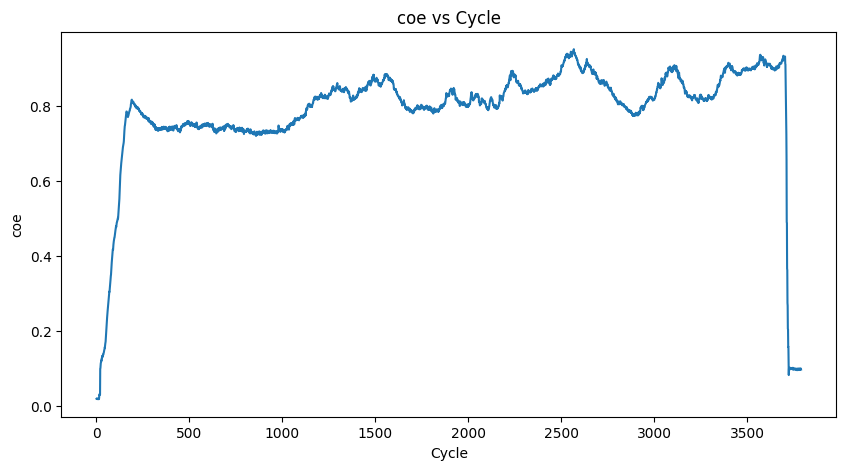

In [7]:
plt.figure(figsize=(10, 5))  # 例如 10英寸宽，5英寸高

plt.plot(df['cycle'], df['coe'])
plt.xlabel('Cycle')
plt.ylabel('coe')
plt.title('coe vs Cycle')
plt.show()

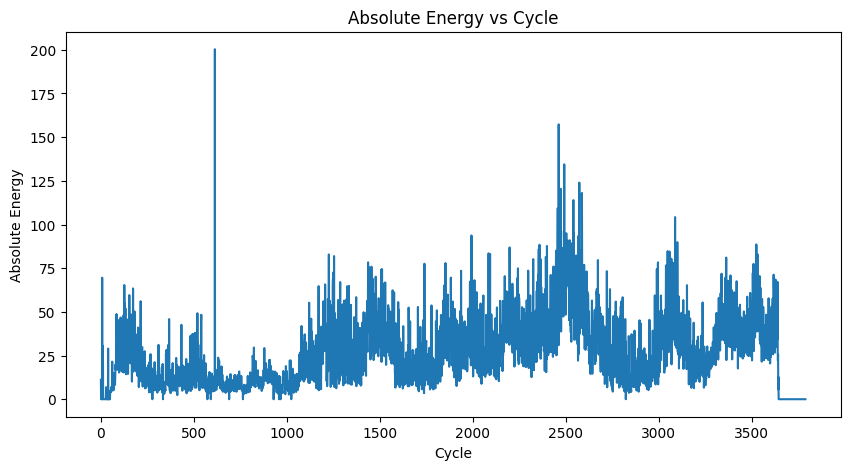

In [8]:
plt.figure(figsize=(10, 5))  # 例如 10英寸宽，5英寸高

plt.plot(df['cycle'], df['Absolute Energy'])
plt.xlabel('Cycle')
plt.ylabel('Absolute Energy')
plt.title('Absolute Energy vs Cycle')
plt.show()